# 50 Startups：依 CRISP-DM 執行多元線性迴歸
使用 sklearn；本 Notebook 已實際執行。

In [1]:
SECTIONS = [('1. 商業理解', '目標：使用研發費用、行政費用、行銷費用及州別預測 Profit，協助進行初步情境估算。這是監督式迴歸問題。事先以優於訓練集平均值基準的 MAE、RMSE 作為教學驗收條件；實際業務容許誤差尚未提供。資料金額單位、期間與抽樣方式未經驗證，不將其視為真實投資依據。', "from pathlib import Path\nimport json, hashlib, platform\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use('Agg')\nimport matplotlib.pyplot as plt\nimport sklearn, joblib\nfrom sklearn.base import clone\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.dummy import DummyRegressor\nfrom sklearn.model_selection import train_test_split, KFold, cross_validate\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\nROOT = Path.cwd()\nOUT = ROOT / 'outputs'\nOUT.mkdir(exist_ok=True)\n"), ('2. 資料理解', '資料為常見 50 Startups 教學 CSV，共五欄。因未提供 Kaggle 檔案，此次使用公開 GitHub 鏡像；不能保證與特定 Kaggle 版本完全相同。先檢查結構與品質，探索關聯則只使用訓練集，避免測試資訊影響建模。保留原始零值及極端值，不任意刪除。', "df = pd.read_csv(ROOT / 'data/50_Startups.csv')\nnum = ['R&D Spend', 'Administration', 'Marketing Spend']\nfeatures = num + ['State']\nassert set(df.columns) == set(features + ['Profit'])\nassert len(df) == 50\nassert df['Profit'].notna().all()\nprint('Shape:', df.shape)\nprint(df.head().to_string(index=False))\nprint('Missing values:', df.isna().sum().to_dict())\nprint('Duplicate rows:', int(df.duplicated().sum()))\nprint('States:', df['State'].value_counts().to_dict())\nX_train, X_test, y_train, y_test = train_test_split(df[features], df['Profit'], test_size=0.2, random_state=42)\nprint('Train/test:', len(X_train), len(X_test))\ntrain = X_train.join(y_train)\nprint(train.describe().to_string())\ncorr = train[num + ['Profit']].corr()\nprint('Training correlation:\\n', corr.to_string())\nfig, axes = plt.subplots(1, 3, figsize=(12, 3.5))\nfor ax, col in zip(axes, num):\n    ax.scatter(X_train[col], y_train)\n    ax.set(xlabel=col, ylabel='Profit')\nfig.tight_layout()\nfig.savefig(OUT / 'training_eda.png', dpi=160)\nplt.show()\nplt.close(fig)\n"), ('3. 資料準備', "三個連續變數保留原尺度，方便解釋係數；普通最小平方法不強制標準化。State 使用 one-hot encoding，drop='first' 以一個州作基準。缺值處理與編碼都放在 Pipeline，僅於各訓練折學習。未知州別預設拒絕，避免默默當作基準州。", "numeric = Pipeline([('impute', SimpleImputer(strategy='median'))])\ncategorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),\n                        ('encode', OneHotEncoder(drop='first', handle_unknown='error', sparse_output=False))])\nprep = ColumnTransformer([('numeric', numeric, num), ('state', categorical, ['State'])])\nmodel = Pipeline([('prepare', prep), ('regression', LinearRegression())])\n"), ('4. 建立模型', '模型形式：Profit = 截距 + 三項費用的線性項 + 州別虛擬變數項。使用 sklearn LinearRegression 最小化殘差平方和。設定固定種子、保留 40 筆訓練及 10 筆測試；在訓練資料內做五折交叉驗證，不依測試分數選特徵或刪除異常值。', "cv = KFold(n_splits=5, shuffle=True, random_state=42)\nscores = cross_validate(model, X_train, y_train, cv=cv,\n    scoring={'MAE':'neg_mean_absolute_error', 'MSE':'neg_mean_squared_error', 'R2':'r2'}, error_score='raise')\ncv_table = pd.DataFrame({'MAE':-scores['test_MAE'], 'RMSE':np.sqrt(-scores['test_MSE']), 'R2':scores['test_R2']})\nprint('Training CV (5 folds):\\n', cv_table.to_string(index=False))\nprint('CV mean:\\n', cv_table.mean().to_string())\nprint('CV standard deviation:\\n', cv_table.std(ddof=1).to_string())\ncv_table.to_csv(OUT / 'cross_validation.csv', index=False)\nmodel.fit(X_train, y_train)\ncoef = pd.DataFrame({'feature': model.named_steps['prepare'].get_feature_names_out(), 'coefficient':model.named_steps['regression'].coef_})\nprint('Intercept:', model.named_steps['regression'].intercept_)\nprint(coef.to_string(index=False))\ncoef.to_csv(OUT / 'coefficients.csv', index=False)\n"), ('5. 模型評估', 'MAE 是絕對誤差平均，RMSE 對大誤差更敏感，兩者均與 Profit 同單位；R² 衡量相對平均值預測的變異解釋程度，可以為負。測試集只評估一次。殘差圖用於觀察曲線、漏斗與極端誤差，並非正式證明常態性、獨立性或等變異成立。樣本僅 50 筆，單次切分結果可能不穩定。', "pred = model.predict(X_test)\nbaseline = DummyRegressor(strategy='mean').fit(X_train, y_train)\ndef metrics(actual, predicted):\n    return {'MAE':float(mean_absolute_error(actual,predicted)), 'RMSE':float(np.sqrt(mean_squared_error(actual,predicted))), 'R2':float(r2_score(actual,predicted))}\nresults = pd.DataFrame({'LinearRegression':metrics(y_test,pred), 'MeanBaseline':metrics(y_test,baseline.predict(X_test))}).T\nprint(results.to_string())\nresults.to_csv(OUT / 'test_metrics.csv')\ncomparison = pd.DataFrame({'row_id':y_test.index, 'actual':y_test.to_numpy(), 'predicted':pred, 'residual':y_test.to_numpy()-pred})\ncomparison.to_csv(OUT / 'test_predictions.csv', index=False)\nprint(comparison.to_string(index=False))\nfig, axes = plt.subplots(1, 3, figsize=(13, 3.7))\naxes[0].scatter(y_test,pred)\nlo, hi = min(y_test.min(),pred.min()), max(y_test.max(),pred.max())\naxes[0].plot([lo,hi],[lo,hi], 'r--')\naxes[0].set(xlabel='Actual Profit',ylabel='Predicted Profit')\naxes[1].scatter(pred,y_test-pred)\naxes[1].axhline(0,color='r',linestyle='--')\naxes[1].set(xlabel='Predicted Profit',ylabel='Residual (actual - predicted)')\naxes[2].hist(y_test-pred,bins=5,edgecolor='black')\naxes[2].set(xlabel='Residual',ylabel='Count')\nfig.tight_layout()\nfig.savefig(OUT / 'test_diagnostics.png',dpi=160)\nplt.show()\nplt.close(fig)\npassed = all(results.loc['LinearRegression',m] < results.loc['MeanBaseline',m] for m in ['MAE','RMSE'])\nprint('Better than baseline on both errors:', passed)\n"), ('6. 部署與維護', '提供本機 Pipeline 模型與單筆預測示範，尚未上線。評估模型使用 40 筆訓練，其測試分數不可套用到後續全資料重訓模型。另以 50 筆重訓教學部署版，沒有額外未見資料可驗證。實務需驗證輸入單位、範圍與州別，累積新樣本並監控 MAE、資料漂移及定期再訓練。係數表示控制其他欄位後的條件關聯，並不代表增加費用就會因果性提高獲利；費用間共線性也會影響係數穩定性。', "joblib.dump(model, OUT / 'evaluation_model.joblib')\ndeployment_model = clone(model).fit(df[features],df['Profit'])\njoblib.dump(deployment_model, OUT / 'deployment_model.joblib')\nexample = pd.DataFrame([{'R&D Spend':100000, 'Administration':120000, 'Marketing Spend':200000, 'State':'New York'}])\nexample_prediction = float(deployment_model.predict(example)[0])\nprint('Example (full-data model):', example_prediction)\nmetadata = {'source_url':'https://raw.githubusercontent.com/SantiagoMorenoV/50-Startups-Multiple-Reg/main/50_Startups.csv',\n 'sha256':hashlib.sha256((ROOT/'data/50_Startups.csv').read_bytes()).hexdigest(),\n 'rows':len(df), 'test_size':0.2, 'random_state':42,\n 'python':platform.python_version(), 'sklearn':sklearn.__version__, 'pandas':pd.__version__, 'numpy':np.__version__,\n 'test_metrics':results.to_dict(orient='index'), 'cv_mean':cv_table.mean().to_dict(),\n 'cv_std':cv_table.std(ddof=1).to_dict(), 'example_prediction':example_prediction}\n(OUT / 'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')\nreport = '# 50 Startups：CRISP-DM 多元線性迴歸分析\\n\\n'\nfor title, explanation, _ in SECTIONS:\n    report += '## ' + title + '\\n\\n' + explanation + '\\n\\n'\nreport += '## 實際執行結果\\n\\n```text\\n' + results.to_string() + '\\n```\\n\\n'\nreport += '訓練集五折交叉驗證（平均 ± 樣本標準差）：\\n\\n'\nfor key in cv_table:\n    report += f'- {key}: {cv_table[key].mean():,.4f} ± {cv_table[key].std(ddof=1):,.4f}\\n'\nreport += '\\n測試集優於平均值基準（MAE、RMSE）：' + str(passed) + '。僅屬教學驗收，正式上線仍需業務誤差門檻及外部驗證。\\n\\n'\nreport += '40 筆訓練模型截距：' + str(model.named_steps['regression'].intercept_) + '\\n\\n```text\\n' + coef.to_string(index=False) + '\\n```\\n\\n'\nreport += '研發費用係數約 ' + str(round(float(coef.iloc[0].coefficient),4)) + '；係數不可直接比較重要性，且不能作因果推論。\\n\\n'\nreport += '![訓練資料探索](outputs/training_eda.png)\\n\\n![測試診斷](outputs/test_diagnostics.png)\\n\\n'\nreport += '資料來源：[公開 CSV 鏡像](' + metadata['source_url'] + ')；[Kaggle 教學頁](https://www.kaggle.com/code/amrut11/multiple-linear-regression-on-50-startups-dataset)。SHA-256：`' + metadata['sha256'] + '`。\\n'\n(ROOT / 'README.md').write_text(report,encoding='utf-8')\n")]

## 1. 商業理解

目標：使用研發費用、行政費用、行銷費用及州別預測 Profit，協助進行初步情境估算。這是監督式迴歸問題。事先以優於訓練集平均值基準的 MAE、RMSE 作為教學驗收條件；實際業務容許誤差尚未提供。資料金額單位、期間與抽樣方式未經驗證，不將其視為真實投資依據。

In [2]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd()
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)


## 2. 資料理解

資料為常見 50 Startups 教學 CSV，共五欄。因未提供 Kaggle 檔案，此次使用公開 GitHub 鏡像；不能保證與特定 Kaggle 版本完全相同。先檢查結構與品質，探索關聯則只使用訓練集，避免測試資訊影響建模。保留原始零值及極端值，不任意刪除。

Shape: (50, 5)
 R&D Spend  Administration  Marketing Spend      State    Profit
 165349.20       136897.80        471784.10   New York 192261.83
 162597.70       151377.59        443898.53 California 191792.06
 153441.51       101145.55        407934.54    Florida 191050.39
 144372.41       118671.85        383199.62   New York 182901.99
 142107.34        91391.77        366168.42    Florida 166187.94
Missing values: {'R&D Spend': 0, 'Administration': 0, 'Marketing Spend': 0, 'State': 0, 'Profit': 0}
Duplicate rows: 0
States: {'New York': 17, 'California': 17, 'Florida': 16}
Train/test: 40 10
           R&D Spend  Administration  Marketing Spend         Profit
count      40.000000       40.000000        40.000000      40.000000
mean    77687.845500   121142.922750    235747.081000  115651.720500
std     47897.502592    27454.110045    114863.931254   42019.018044
min         0.000000    51283.140000         0.000000   14681.400000
25%     40241.045000   102579.505000    160353.310000  

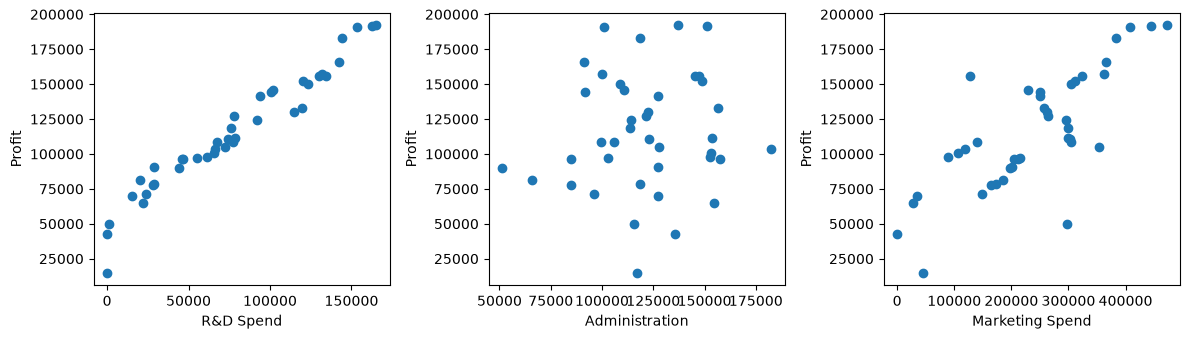

In [3]:
df = pd.read_csv(ROOT / 'data/50_Startups.csv')
num = ['R&D Spend', 'Administration', 'Marketing Spend']
features = num + ['State']
assert set(df.columns) == set(features + ['Profit'])
assert len(df) == 50
assert df['Profit'].notna().all()
print('Shape:', df.shape)
print(df.head().to_string(index=False))
print('Missing values:', df.isna().sum().to_dict())
print('Duplicate rows:', int(df.duplicated().sum()))
print('States:', df['State'].value_counts().to_dict())
X_train, X_test, y_train, y_test = train_test_split(df[features], df['Profit'], test_size=0.2, random_state=42)
print('Train/test:', len(X_train), len(X_test))
train = X_train.join(y_train)
print(train.describe().to_string())
corr = train[num + ['Profit']].corr()
print('Training correlation:\n', corr.to_string())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, num):
    ax.scatter(X_train[col], y_train)
    ax.set(xlabel=col, ylabel='Profit')
fig.tight_layout()
fig.savefig(OUT / 'training_eda.png', dpi=160)
plt.show()
plt.close(fig)


## 3. 資料準備

三個連續變數保留原尺度，方便解釋係數；普通最小平方法不強制標準化。State 使用 one-hot encoding，drop='first' 以一個州作基準。缺值處理與編碼都放在 Pipeline，僅於各訓練折學習。未知州別預設拒絕，避免默默當作基準州。

In [4]:
numeric = Pipeline([('impute', SimpleImputer(strategy='median'))])
categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                        ('encode', OneHotEncoder(drop='first', handle_unknown='error', sparse_output=False))])
prep = ColumnTransformer([('numeric', numeric, num), ('state', categorical, ['State'])])
model = Pipeline([('prepare', prep), ('regression', LinearRegression())])


## 4. 建立模型

模型形式：Profit = 截距 + 三項費用的線性項 + 州別虛擬變數項。使用 sklearn LinearRegression 最小化殘差平方和。設定固定種子、保留 40 筆訓練及 10 筆測試；在訓練資料內做五折交叉驗證，不依測試分數選特徵或刪除異常值。

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, X_train, y_train, cv=cv,
    scoring={'MAE':'neg_mean_absolute_error', 'MSE':'neg_mean_squared_error', 'R2':'r2'}, error_score='raise')
cv_table = pd.DataFrame({'MAE':-scores['test_MAE'], 'RMSE':np.sqrt(-scores['test_MSE']), 'R2':scores['test_R2']})
print('Training CV (5 folds):\n', cv_table.to_string(index=False))
print('CV mean:\n', cv_table.mean().to_string())
print('CV standard deviation:\n', cv_table.std(ddof=1).to_string())
cv_table.to_csv(OUT / 'cross_validation.csv', index=False)
model.fit(X_train, y_train)
coef = pd.DataFrame({'feature': model.named_steps['prepare'].get_feature_names_out(), 'coefficient':model.named_steps['regression'].coef_})
print('Intercept:', model.named_steps['regression'].intercept_)
print(coef.to_string(index=False))
coef.to_csv(OUT / 'coefficients.csv', index=False)


Training CV (5 folds):
          MAE         RMSE       R2
 7946.608531  9794.974940 0.953948
 7175.207441  8777.265241 0.954346
10346.959117 14900.982314 0.893257
 4914.887143  6091.626974 0.971281
 6745.745396  8188.531059 0.897187
CV mean:
 MAE     7425.881525
RMSE    9550.676106
R2         0.934004
CV standard deviation:
 MAE     1977.015829
RMSE    3282.684985
R2         0.036114
Intercept: 54028.039593645815
                 feature  coefficient
      numeric__R&D Spend     0.805630
 numeric__Administration    -0.068788
numeric__Marketing Spend     0.029855
    state__State_Florida   938.793006
   state__State_New York     6.987760


## 5. 模型評估

MAE 是絕對誤差平均，RMSE 對大誤差更敏感，兩者均與 Profit 同單位；R² 衡量相對平均值預測的變異解釋程度，可以為負。測試集只評估一次。殘差圖用於觀察曲線、漏斗與極端誤差，並非正式證明常態性、獨立性或等變異成立。樣本僅 50 筆，單次切分結果可能不穩定。

                           MAE          RMSE        R2
LinearRegression   6961.477813   9055.957323  0.898727
MeanBaseline      25295.290200  33776.691540 -0.408837
 row_id    actual     predicted      residual
     13 134307.35 126362.879083   7944.470917
     39  81005.76  84608.453836  -3602.693836
     30  99937.59  99677.494251    260.095749
     45  64926.08  46357.460686  18568.619314
     17 125370.37 128750.482885  -3380.112885
     48  35673.41  50912.417419 -15239.007419
     26 105733.54 109741.350327  -4007.810327
     25 107404.34 100643.242816   6761.097184
     32  97427.84  97599.275746   -171.435746
     19 122776.86 113097.425244   9679.434756


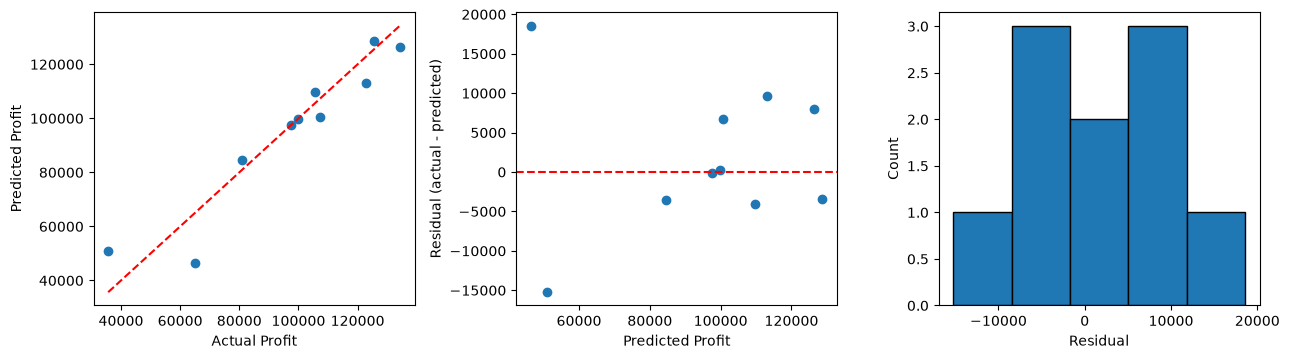

Better than baseline on both errors: True


In [6]:
pred = model.predict(X_test)
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
def metrics(actual, predicted):
    return {'MAE':float(mean_absolute_error(actual,predicted)), 'RMSE':float(np.sqrt(mean_squared_error(actual,predicted))), 'R2':float(r2_score(actual,predicted))}
results = pd.DataFrame({'LinearRegression':metrics(y_test,pred), 'MeanBaseline':metrics(y_test,baseline.predict(X_test))}).T
print(results.to_string())
results.to_csv(OUT / 'test_metrics.csv')
comparison = pd.DataFrame({'row_id':y_test.index, 'actual':y_test.to_numpy(), 'predicted':pred, 'residual':y_test.to_numpy()-pred})
comparison.to_csv(OUT / 'test_predictions.csv', index=False)
print(comparison.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
axes[0].scatter(y_test,pred)
lo, hi = min(y_test.min(),pred.min()), max(y_test.max(),pred.max())
axes[0].plot([lo,hi],[lo,hi], 'r--')
axes[0].set(xlabel='Actual Profit',ylabel='Predicted Profit')
axes[1].scatter(pred,y_test-pred)
axes[1].axhline(0,color='r',linestyle='--')
axes[1].set(xlabel='Predicted Profit',ylabel='Residual (actual - predicted)')
axes[2].hist(y_test-pred,bins=5,edgecolor='black')
axes[2].set(xlabel='Residual',ylabel='Count')
fig.tight_layout()
fig.savefig(OUT / 'test_diagnostics.png',dpi=160)
plt.show()
plt.close(fig)
passed = all(results.loc['LinearRegression',m] < results.loc['MeanBaseline',m] for m in ['MAE','RMSE'])
print('Better than baseline on both errors:', passed)


## 6. 部署與維護

提供本機 Pipeline 模型與單筆預測示範，尚未上線。評估模型使用 40 筆訓練，其測試分數不可套用到後續全資料重訓模型。另以 50 筆重訓教學部署版，沒有額外未見資料可驗證。實務需驗證輸入單位、範圍與州別，累積新樣本並監控 MAE、資料漂移及定期再訓練。係數表示控制其他欄位後的條件關聯，並不代表增加費用就會因果性提高獲利；費用間共線性也會影響係數穩定性。

In [7]:
joblib.dump(model, OUT / 'evaluation_model.joblib')
deployment_model = clone(model).fit(df[features],df['Profit'])
joblib.dump(deployment_model, OUT / 'deployment_model.joblib')
example = pd.DataFrame([{'R&D Spend':100000, 'Administration':120000, 'Marketing Spend':200000, 'State':'New York'}])
example_prediction = float(deployment_model.predict(example)[0])
print('Example (full-data model):', example_prediction)
metadata = {'source_url':'https://raw.githubusercontent.com/SantiagoMorenoV/50-Startups-Multiple-Reg/main/50_Startups.csv',
 'sha256':hashlib.sha256((ROOT/'data/50_Startups.csv').read_bytes()).hexdigest(),
 'rows':len(df), 'test_size':0.2, 'random_state':42,
 'python':platform.python_version(), 'sklearn':sklearn.__version__, 'pandas':pd.__version__, 'numpy':np.__version__,
 'test_metrics':results.to_dict(orient='index'), 'cv_mean':cv_table.mean().to_dict(),
 'cv_std':cv_table.std(ddof=1).to_dict(), 'example_prediction':example_prediction}
(OUT / 'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
report = '# 50 Startups：CRISP-DM 多元線性迴歸分析\n\n'
for title, explanation, _ in SECTIONS:
    report += '## ' + title + '\n\n' + explanation + '\n\n'
report += '## 實際執行結果\n\n```text\n' + results.to_string() + '\n```\n\n'
report += '訓練集五折交叉驗證（平均 ± 樣本標準差）：\n\n'
for key in cv_table:
    report += f'- {key}: {cv_table[key].mean():,.4f} ± {cv_table[key].std(ddof=1):,.4f}\n'
report += '\n測試集優於平均值基準（MAE、RMSE）：' + str(passed) + '。僅屬教學驗收，正式上線仍需業務誤差門檻及外部驗證。\n\n'
report += '40 筆訓練模型截距：' + str(model.named_steps['regression'].intercept_) + '\n\n```text\n' + coef.to_string(index=False) + '\n```\n\n'
report += '研發費用係數約 ' + str(round(float(coef.iloc[0].coefficient),4)) + '；係數不可直接比較重要性，且不能作因果推論。\n\n'
report += '![訓練資料探索](outputs/training_eda.png)\n\n![測試診斷](outputs/test_diagnostics.png)\n\n'
report += '資料來源：[公開 CSV 鏡像](' + metadata['source_url'] + ')；[Kaggle 教學頁](https://www.kaggle.com/code/amrut11/multiple-linear-regression-on-50-startups-dataset)。SHA-256：`' + metadata['sha256'] + '`。\n'
(ROOT / 'README.md').write_text(report,encoding='utf-8')


Example (full-data model): 132841.2220421545


1981